# Άσκηση 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar
import math

## Γραφική Παράσταση:

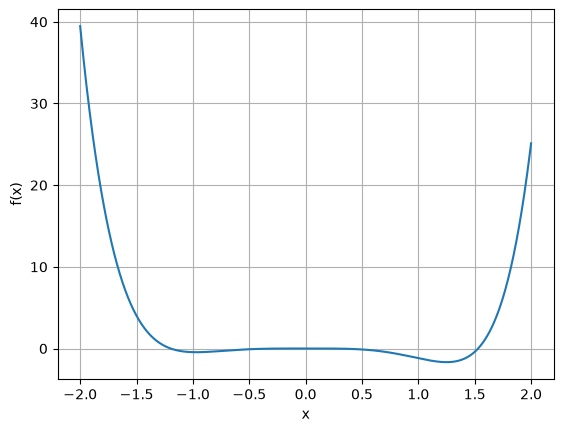

In [2]:
x=np.linspace(-2,2,1000)
y=np.exp(np.sin(x)**3) + x**6 - 2*x**4 - x**3 - 1
plt.plot(x,y)
plt.grid(True, axis='both')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.show()

In [3]:
def f(x):
    return np.expm1(np.sin(x)**3) + x**6 - 2*x**4 - x**3

def df(x):
    return (3 * np.exp(np.sin(x)**3) *
            np.sin(x)**2 * np.cos(x)
            + 6*x**5 - 8*x**3 - 3*x**2)

## Διχοτόμηση
Η μέθοδος της διχοτόμησης δεν μπορεί να εφαρμοστεί για τη ρίζα x = 0, επειδή η f(x) είναι αρνητική τόσο αριστερά όσο και δεξιά του 0. 

In [4]:
def bisection(f, a, b, tol, max_iter):

    if f(a)*f(b)>=0:
        return None, 0

    i=0

    while abs(b-a)/2.0>=tol and i<max_iter:
        c=(a+b)/2.0
        if f(c)==0:
            return c, i
        i+=1
        if f(a)*f(c)<0:
            b=c
        else:
            a=c
    return (a+b)/2.0, i



## Newton-Raphson

In [5]:
def newton_raphson(f, df, x0, tol, max_iter):

    x=x0
    i=0

    fx=f(x)
    dfx=df(x)

    if dfx==0:
        print('df=0')
        return x, i

    x_new=x-fx/dfx
    err=abs(x_new-x)
    x=x_new
    i+=1

    while err>=tol and i<max_iter:

        fx=f(x)
        dfx=df(x)

        if dfx==0:
            print('df=0')
            break

        x_new=x-fx/dfx
        err=abs(x_new-x)
        x=x_new
        i+=1
        
    return x, i


## Μέθοδος Τέμνουσας

In [6]:
def secant(f,x0, x1, tol, max_iter):

    i=0

    f0, f1=f(x0),f(x1)

    if f1-f0==0:
        return x1, i
    
    x2=x1-f1*(x1-x0)/(f1-f0)
    x0, x1 = x1, x2
    i+=1

    while abs(x1-x0)>=tol and i<max_iter:
        f0, f1=f(x0),f(x1)
        if f1-f0==0:
            break
        x2=x1-f1*(x1-x0)/(f1-f0)
        x0, x1 = x1, x2
        i+=1
    return x1, i

In [7]:

np.random.seed(42)

# r1 (≈ -1.1976235):
bis_r1, new_r1, sec_r1 = [], [], []

for i in range(10):
  # bisection
  a = np.random.uniform(-1.4, -1.20)
  b = np.random.uniform(-1.19, -1.0)
  _, iters_b = bisection(f, a, b, tol=1e-8, max_iter=200)
  bis_r1.append(iters_b)

  # newton-raphson
  x0 = np.random.uniform(-1.3, -1.0)
  _, iters_n = newton_raphson(f, df, x0, tol=1e-8, max_iter=200)
  new_r1.append(iters_n)

  # secant
  x0, x1 = np.random.uniform(-1.4, -1.0, size=2)
  _, iters_s = secant(f, x0, x1, tol=1e-8, max_iter=200)
  sec_r1.append(iters_s)

# r2 (= 0):
new_r2, sec_r2 = [], []

for i in range(10):
  # newton-raphson
  x0 = np.random.uniform(-0.05, 0.05)
  _, iters_n = newton_raphson(f, df, x0, tol=1e-10, max_iter=200)
  new_r2.append(iters_n)

  # secant
  x0, x1 = np.random.uniform(-0.05, 0.05, size=2)
  _, iters_s = secant(f, x0, x1, tol=1e-10, max_iter=200)
  sec_r2.append(iters_s)

# r3 (≈ 1.5301336):
bis_r3, new_r3, sec_r3 = [], [], []

for i in range(10):
  # bisection
  a = np.random.uniform(1.35, 1.50)
  b = np.random.uniform(1.55, 1.70)
  _, iters_b = bisection(f, a, b, tol=1e-8, max_iter=200)
  bis_r3.append(iters_b)

  # newton-raphson
  x0 = np.random.uniform(1.4, 1.6)
  _, iters_n = newton_raphson(f, df, x0, tol=1e-8, max_iter=200)
  new_r3.append(iters_n)

  # secant
  x0, x1 = np.random.uniform(1.4, 1.6, size=2)
  _, iters_s = secant(f, x0, x1, tol=1e-8, max_iter=200)
  sec_r3.append(iters_s)


def print_stats(title, lst):
  print(
      f"{title:<16} -> Min: {min(lst):2d} | Mean: {np.mean(lst):5.1f} | Max:"
      f" {max(lst):2d}"
  )


print("--- 1η Ρίζα ---")
print_stats("Διχοτόμηση", bis_r1)
print_stats("Newton-Raphson", new_r1)
print_stats("Τέμνουσα", sec_r1)

print("\n--- 2η Ρίζα ---")
print("Διχοτόμηση       -> Δεν εφαρμόζεται")
print_stats("Newton-Raphson", new_r2)
print_stats("Τέμνουσα", sec_r2)

print("\n--- 3η Ρίζα ---")
print_stats("Διχοτόμηση", bis_r3)
print_stats("Newton-Raphson", new_r3)
print_stats("Τέμνουσα", sec_r3)

--- 1η Ρίζα ---
Διχοτόμηση       -> Min: 23 | Mean:  23.6 | Max: 25
Newton-Raphson   -> Min:  4 | Mean:   5.5 | Max:  8
Τέμνουσα         -> Min:  5 | Mean:   7.0 | Max: 13

--- 2η Ρίζα ---
Διχοτόμηση       -> Δεν εφαρμόζεται
Newton-Raphson   -> Min: 58 | Mean:  64.3 | Max: 66
Τέμνουσα         -> Min: 87 | Mean:  90.0 | Max: 93

--- 3η Ρίζα ---
Διχοτόμηση       -> Min: 23 | Mean:  23.9 | Max: 24
Newton-Raphson   -> Min:  3 | Mean:   4.6 | Max:  5
Τέμνουσα         -> Min:  4 | Mean:   6.0 | Max:  7


In [ ]:
def newton_raphson_history(f, df, x0, tol, max_iter):
  x = x0
  i = 0
  history = [x]

  fx = f(x)
  dfx = df(x)
  if dfx == 0:
    return x, i, history

  x_new = x - fx / dfx
  err = abs(x_new - x)
  x = x_new
  history.append(x)
  i += 1

  while err >= tol and i < max_iter:
    fx = f(x)
    dfx = df(x)
    if dfx == 0:
      break

    x_new = x - fx / dfx
    err = abs(x_new - x)
    x = x_new
    history.append(x)
    i += 1

  return x, i, history

In [12]:
r1_true, _ = newton_raphson(f, df, -1.2, 1e-15, 200)
r2_true = 0.0
r3_true, _ = newton_raphson(f, df, 1.5, 1e-15, 200)
print(r1_true, ', ', r2_true, ', ', r3_true)

-1.19762372213357 ,  0.0 ,  1.5301335081666156


In [ ]:
x, i, history=newton_raphson_history(f, df, -1.1, tol=1e-8, max_iter=200)
errs = []
j = 0
  while j < len(hist):
    e = abs(hist[j] - r_true)
    if e > 1e-14:
      errs.append(e)
    j += 1